# U03.E06 · Autoencoder y VAE sobre Fashion-MNIST: resultados

**Estudiante:** Johanna Joaquín · INF-8239 Ciencia de Datos II · UASD

Este cuaderno lee los resultados que genera `scripts/e06_evaluacion.py` (carpeta `reports/`) y los interpreta. Para volver a generarlos ejecute primero ese script (5 a 8 minutos en CPU) o cambie `RUN_EXPERIMENT` a `True`. Fashion-MNIST (licencia MIT) no se incluye en el repositorio: Keras lo descarga.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
RUN_EXPERIMENT = False  # True vuelve a ejecutar la evaluación completa (5 a 8 minutos)

if RUN_EXPERIMENT:
    env = {**os.environ, "PYTHONUTF8": "1"}
    subprocess.run([sys.executable, str(ROOT / "scripts" / "e06_evaluacion.py"), "--seeds", "42", "43", "44"],
                   cwd=ROOT, env=env, check=True)

runs = pd.read_csv(REPORTS / "e06_resultados_por_semilla.csv")
info = json.loads((REPORTS / "e06_resumen.json").read_text(encoding="utf-8"))
ORDER = ["AE-16 con N(0,I)", "AE-16 gaussiana ajustada", "AE-2 gaussiana ajustada", "VAE-2", "VAE-16"]
print("Semillas:", info["seeds"], "| TensorFlow", info["tensorflow"], "| Python", info["python"])
print("Piso de ruido de Fréchet (real contra real):", round(info["frechet_noise_floor_real_vs_real"], 1))

Semillas: [42, 43, 44] | TensorFlow 2.21.0 | Python 3.12.13
Piso de ruido de Fréchet (real contra real): 3.8


## 1. Tabla principal (media ± desviación entre 3 semillas)

In [2]:
COLUMNS = [("recon_mse_test", "MSE recon.", 4), ("frechet_pixels", "Fréchet", 1), ("diversity_ratio", "Diversidad", 2),
           ("classes_covered", "Clases", 1), ("classifier_confidence", "Confianza", 2), ("nn_ratio", "Vecino/real", 2),
           ("near_copy_share", "Casi copias", 3), ("train_seconds", "Entren. (s)", 1), ("params", "Parámetros", 0)]
rows = {}
for model in ORDER:
    part = runs[runs.model == model]
    rows[model] = {title: f"{part[key].mean():.{d}f} ± {part[key].std(ddof=1):.{d}f}" for key, title, d in COLUMNS}
table = pd.DataFrame(rows).T
table

,MSE recon.,Fréchet,Diversidad,Clases,Confianza,Vecino/real,Casi copias,Entren. (s),Parámetros
"AE-16 con N(0,I)",0.0206 ± 0.0004,95.0 ± 0.1,0.46 ± 0.05,1.3 ± 0.6,0.97 ± 0.01,1.79 ± 0.01,0.000 ± 0.000,7.3 ± 1.3,25888 ± 0
AE-16 gaussiana ajustada,0.0206 ± 0.0004,15.3 ± 1.1,0.88 ± 0.01,10.0 ± 0.0,0.68 ± 0.02,1.33 ± 0.01,0.000 ± 0.001,7.3 ± 1.3,25888 ± 0
AE-2 gaussiana ajustada,0.0585 ± 0.0001,44.8 ± 0.7,0.65 ± 0.01,8.3 ± 0.6,0.54 ± 0.02,1.14 ± 0.01,0.000 ± 0.000,7.1 ± 0.2,3922 ± 0
VAE-2,0.0330 ± 0.0001,36.8 ± 4.4,0.55 ± 0.04,9.3 ± 0.6,0.55 ± 0.03,0.77 ± 0.04,0.142 ± 0.032,15.4 ± 0.6,202516 ± 0
VAE-16,0.0165 ± 0.0001,17.5 ± 0.7,0.68 ± 0.01,10.0 ± 0.0,0.66 ± 0.01,1.09 ± 0.02,0.002 ± 0.002,14.8 ± 0.4,207920 ± 0


**Cómo leerla.** Menor es mejor en MSE y Fréchet. Una diversidad de 1 significa tan variadas como las imágenes reales. *Vecino/real* menor que 1 indica muestras más cerca del entrenamiento que imágenes reales nuevas (posible memoria, pero ver sección 4). La comparación AE contra VAE está confundida por capacidad: el AE del laboratorio no tiene capa oculta (26 mil parámetros) y el VAE sí (cerca de 200 mil).

## 2. Reconstrucción y calidad de las muestras

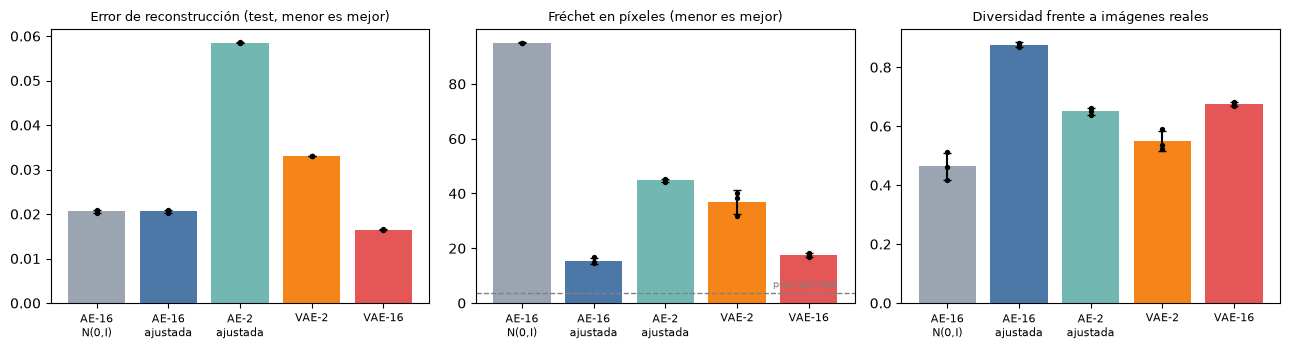

In [3]:
colors = ["#9aa5b1", "#4c78a8", "#72b7b2", "#f58518", "#e45756"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for axis, (key, title) in zip(axes, [("recon_mse_test", "Error de reconstrucción (test, menor es mejor)"),
                                     ("frechet_pixels", "Fréchet en píxeles (menor es mejor)"),
                                     ("diversity_ratio", "Diversidad frente a imágenes reales")]):
    means = [runs[runs.model == m][key].mean() for m in ORDER]
    stds = [runs[runs.model == m][key].std(ddof=1) for m in ORDER]
    axis.bar(range(len(ORDER)), means, yerr=stds, color=colors, capsize=3)
    for position, model in enumerate(ORDER):
        axis.scatter([position] * 3, runs[runs.model == model][key], color="black", s=8, zorder=3)
    axis.set_xticks(range(len(ORDER)))
    axis.set_xticklabels(["AE-16\nN(0,I)", "AE-16\najustada", "AE-2\najustada", "VAE-2", "VAE-16"], fontsize=8)
    axis.set_title(title, fontsize=9)
axes[1].axhline(info["frechet_noise_floor_real_vs_real"], color="gray", linestyle="--", linewidth=1)
axes[1].text(4.4, info["frechet_noise_floor_real_vs_real"] + 2, "piso real-real", ha="right", fontsize=7, color="gray")
fig.tight_layout()
plt.show()

- VAE-16 reconstruye mejor que AE-16, pero con unas 8 veces más parámetros.
- Con 2 dimensiones el error se duplica o casi se triplica: el espacio latente es demasiado pequeño para 10 clases.
- Un AE muestreado con `N(0, I)` no es un generador (Fréchet 95, una sola clase). Con una gaussiana ajustada se acerca al VAE-16; con 3 semillas la diferencia entre ambos es pequeña.
- Ninguno se acerca al piso de ruido: las muestras son borrosas.

## 3. Figuras con ejemplos no seleccionados

e06_panel_reconstruccion.png


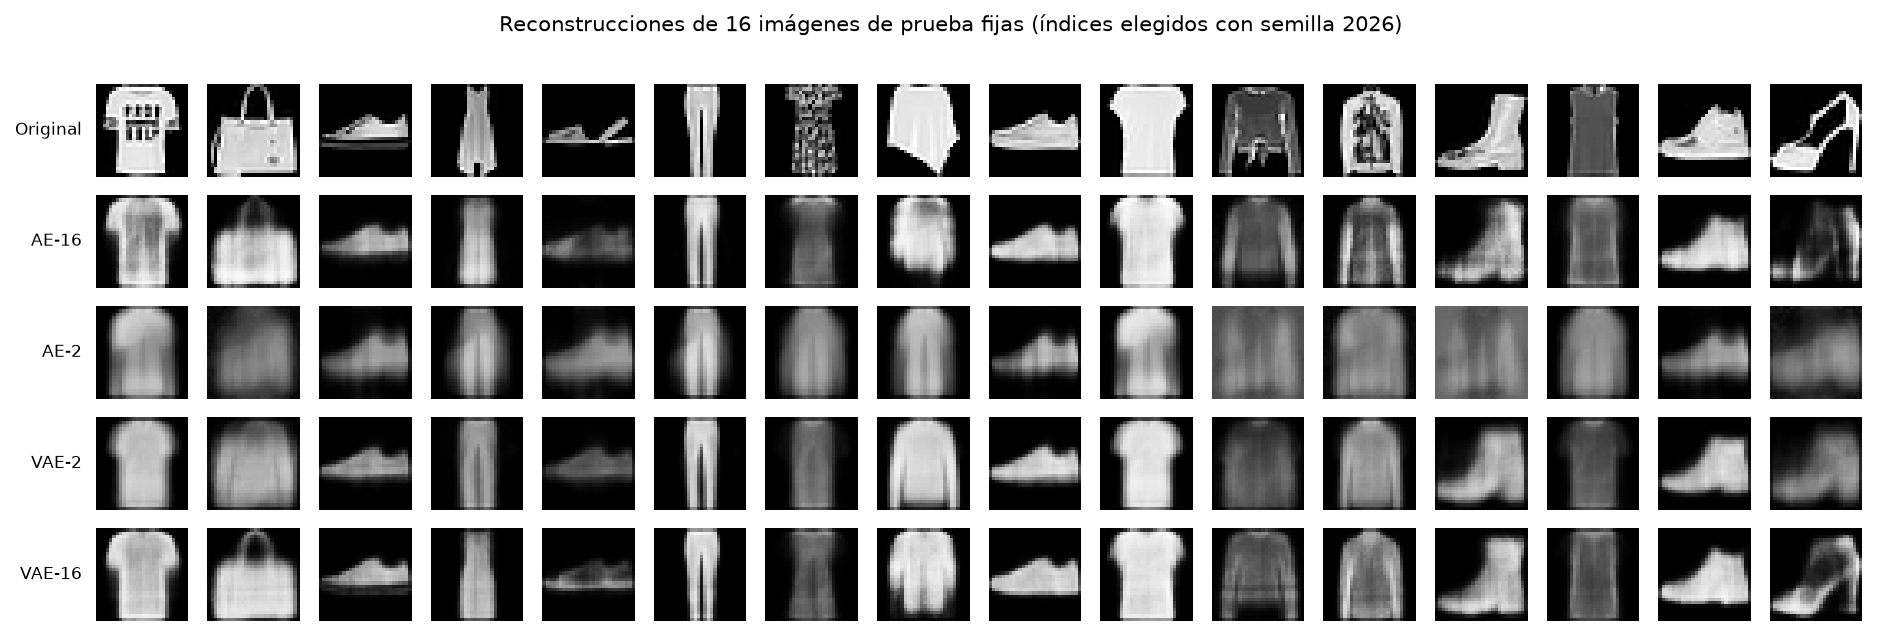

e06_muestras.png


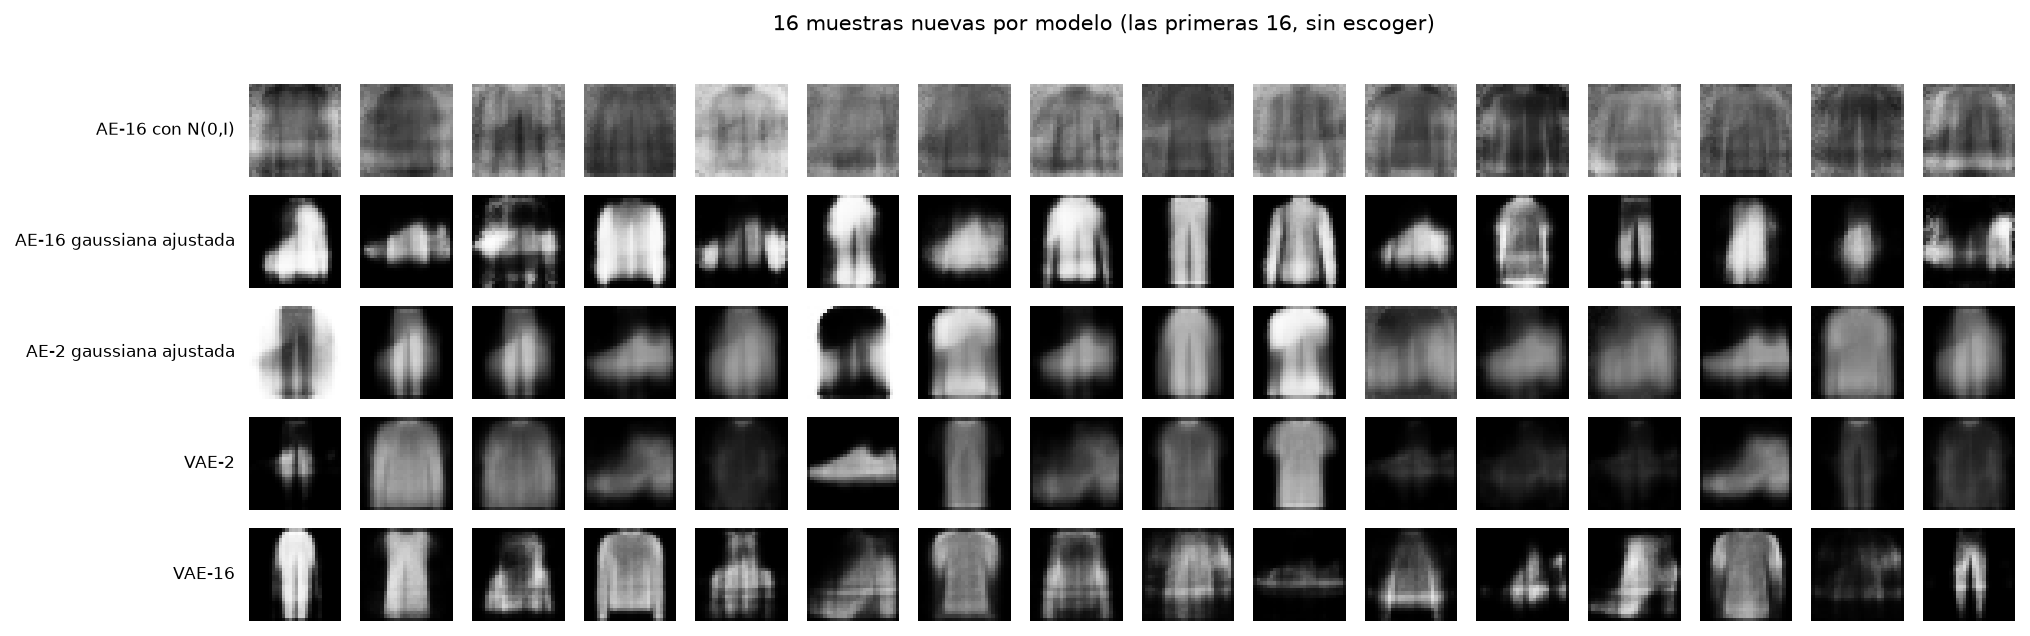

e06_interpolacion.png


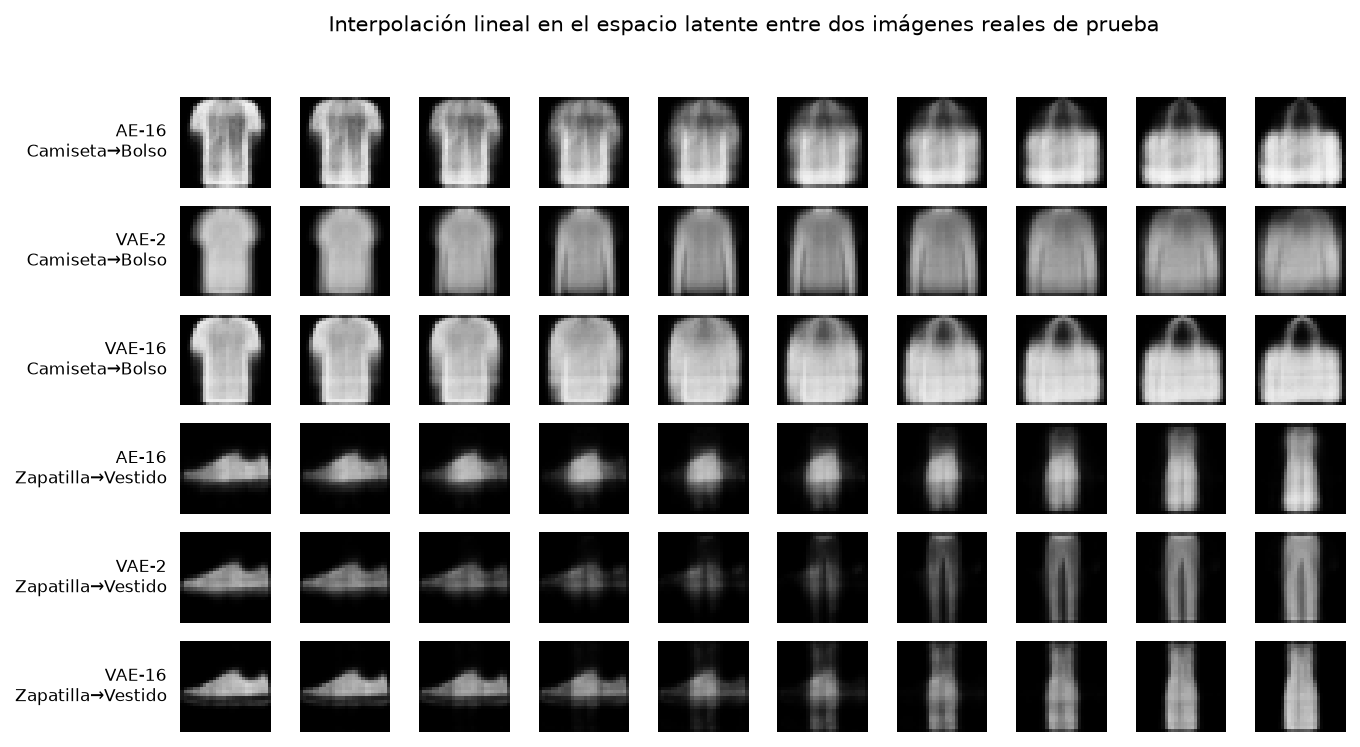

Índices de prueba fijos (semilla 2026 ): [263, 797, 1773, 1786, 3547, 3650, 3702, 4668, 6391, 6430, 7042, 7211, 7902, 8306, 8505, 9049]


In [4]:
for name in ["e06_panel_reconstruccion.png", "e06_muestras.png", "e06_interpolacion.png"]:
    print(name)
    display(Image(filename=str(REPORTS / name)))
print("Índices de prueba fijos (semilla", info["fixed_indices_seed"], "):", info["fixed_indices"])

Los 16 ejemplos de reconstrucción se eligieron con una semilla, no a mano. En las muestras se ve cómo el AE con `N(0, I)` produce una misma silueta borrosa, mientras que los VAE producen prendas variadas, aunque poco nítidas. En la interpolación, AE-16 y VAE-16 pasan de una prenda a otra mezclándolas gradualmente; VAE-2 reconstruye el vestido como pantalón, lo que muestra la pérdida de información de un latente de 2 dimensiones.

## 4. Memoria: ¿las muestras copian el entrenamiento?

,nn_ratio,near_copy_share,exact_copy_share,recon_gap
model,,,,
"AE-16 con N(0,I)",1.7921,0.0000,0.0,0.0001
AE-16 gaussiana ajustada,1.3256,0.0003,0.0,0.0001
AE-2 gaussiana ajustada,1.1361,0.0000,0.0,-0.0003
VAE-2,0.7664,0.1417,0.0,-0.0001
VAE-16,1.0860,0.0020,0.0,0.0001


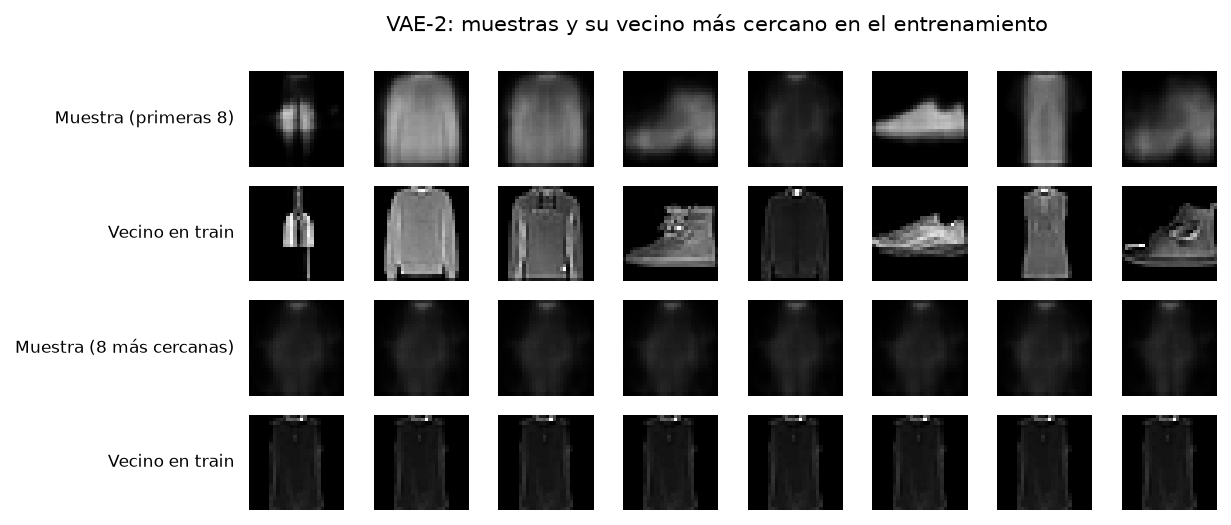

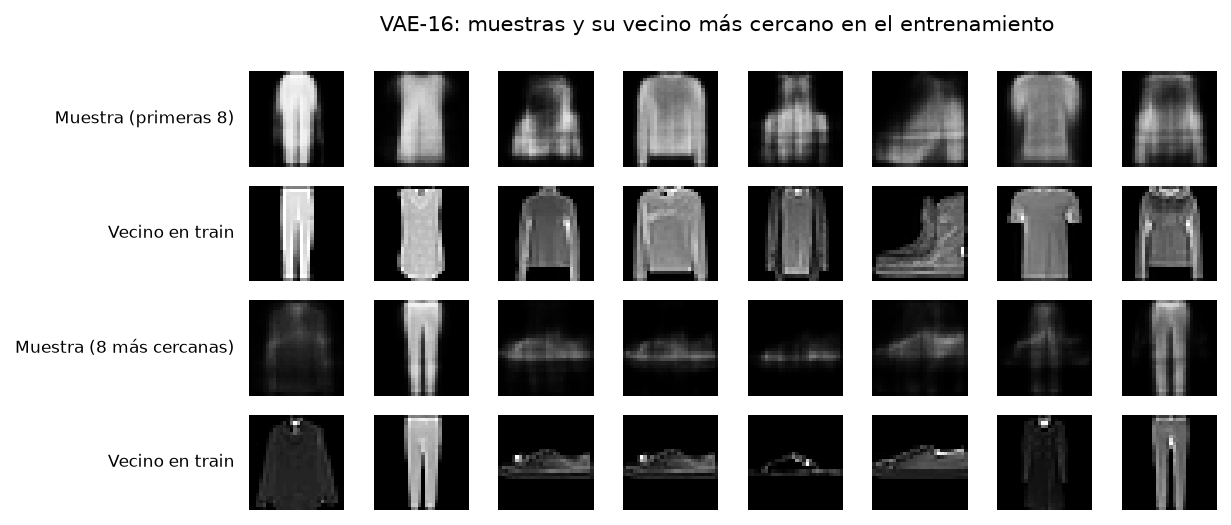

In [5]:
memory = runs.groupby("model")[["nn_ratio", "near_copy_share", "exact_copy_share", "recon_gap"]].mean().loc[ORDER]
display(memory.round(4))
for name in ["e06_memoria_vae2.png", "e06_memoria_vae16.png"]:
    display(Image(filename=str(REPORTS / name)))
assert (runs.exact_copy_share == 0).all(), "se encontraron copias exactas"
assert runs.recon_gap.abs().max() < 1e-3, "hay brecha entre entrenamiento y prueba"

No hay copias exactas y la brecha de reconstrucción entre entrenamiento y prueba es del orden de 1e-4, así que no se observa sobreajuste. VAE-2 sí muestra *Vecino/real* de 0.77 y 14 % de casi copias, pero las figuras revelan que sus muestras más cercanas son manchas casi negras cuyo vecino es una prenda oscura: una explicación plausible (hipótesis no demostrada) es que la distancia en píxeles sea pequeña porque ambas imágenes son oscuras. **La métrica es sensible al brillo y por sí sola ni prueba ni descarta memorización**, por eso se revisó con imágenes; comprobar la hipótesis con una distancia que no dependa del brillo queda pendiente. El resto de modelos tiene muestras más lejanas del entrenamiento que las imágenes reales (*Vecino/real* mayor que 1), típico de muestras borrosas.

## 5. Espacio latente de VAE-2

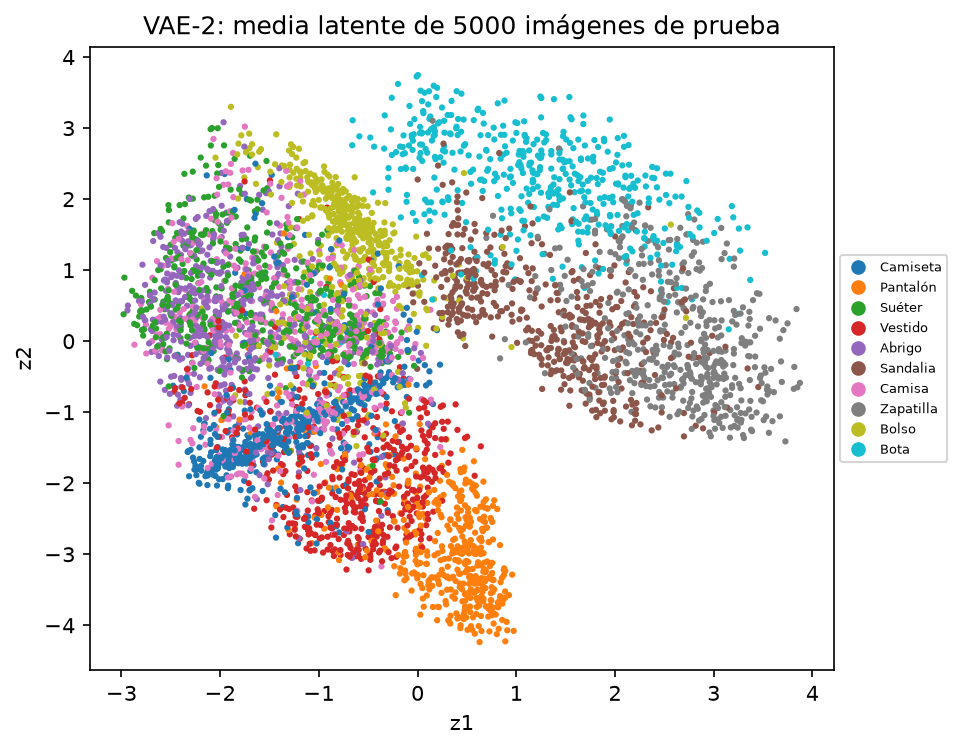

In [6]:
display(Image(filename=str(REPORTS / "e06_latente_vae2.png")))

Los calzados (sandalia, zapatilla, bota) quedan arriba a la derecha; pantalón y vestido, abajo; y camiseta, camisa, suéter y abrigo se superponen arriba a la izquierda. Es una estructura razonable, pero con mucho solapamiento, y explica los errores de reconstrucción.

## 6. Costo

In [7]:
cost = runs.groupby("model")[["train_seconds", "params", "size_kb", "infer_ms_per_1000"]].agg(["mean", "std"]).loc[ORDER].round(1)
cost

train_seconds         params      size_kb       \
                                  mean  std      mean  std    mean  std   
model                                                                     
AE-16 con N(0,I)                   7.3  1.3   25888.0  0.0   330.7  0.0   
AE-16 gaussiana ajustada           7.3  1.3   25888.0  0.0   330.7  0.0   
AE-2 gaussiana ajustada            7.1  0.2    3922.0  0.0    73.2  0.0   
VAE-2                             15.4  0.6  202516.0  0.0   832.9  0.0   
VAE-16                            14.8  0.4  207920.0  0.0   854.1  0.0   

                         infer_ms_per_1000        
                                      mean   std  
model                                             
AE-16 con N(0,I)                     224.5  16.3  
AE-16 gaussiana ajustada             216.7  27.8  
AE-2 gaussiana ajustada              204.3  15.0  
VAE-2                                233.5  34.1  
VAE-16                               211.6   6.1

El VAE cuesta el doble de tiempo (unos 15 s contra 7 s), 8 veces más parámetros y 2.6 veces más espacio en disco que AE-16. Los tiempos de inferencia (unos 200 ms por 1,000 imágenes) no difieren más que su variación entre corridas.

## 7. Conclusión y decisión (resultados exploratorios de este dominio)

- **Generador de referencia: VAE-16.** Mejor reconstrucción, cubre las 10 clases y se muestrea directamente de `N(0, I)`.
- **Alternativa barata: AE-16 con gaussiana ajustada.** Calidad de muestras comparable con 8 veces menos parámetros, pero necesita un paso de ajuste posterior.
- **VAE-2 solo para visualización.** Como generador es peor (Fréchet 36.8) y produce muestras tenues.
- **Límites:** dominio simple (28×28 en gris), entrenamiento corto, 3 semillas, métricas aproximadas (Fréchet en píxeles; clasificador auxiliar con exactitud de 0.85), sin auditoría de privacidad. Uso académico y exploratorio; ver `MODEL_CARD.md`.